# Breadth of US Growth: Simplified

Data come from BEA GDP by Industry via the API, using three tables:
- **8:** chain-type quantity indexes for real value added, used for growth rates
- **13:** contributions to real GDP growth
- **5:** nominal value added as % of GDP, used for weights

Notes on the measures:
- Every share chart uses a 2-quarter moving average.
- **Weighted** shares weight each industry by its prior-period nominal share of value added.
- For the y/y view, contribution measures use the trailing 4-quarter average of quarterly contributions.
- **Breadth composite:** the average z-score of four measures:
  - share growing
  - weighted share growing
  - share growing faster than its own prior-3-year pace
  - the negative of the top-3 share of positive contributions

  The z-scores exclude 2020Q2–Q3 when estimating the mean and standard deviation.

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

KEY = "FD4E7F46-5D89-4CA8-BE48-4F5997F83B3B"

SECTORS = ["11", "21", "22", "23", "33DG", "31ND", "42", "44RT", "48TW", "51", "52", "53", "54", "55",
           "56", "61", "62", "71", "72", "81", "GF", "GSL"]
INDUSTRIES = ["111CA", "113FF", "211", "212", "213", "22", "23", "321", "327", "331", "332", "333", "334",
              "335", "3361MV", "3364OT", "337", "339", "311FT", "313TT", "315AL", "322", "323", "324", "325",
              "326", "42", "441", "445", "452", "4A0", "481", "482", "483", "484", "485", "486", "487OS",
              "493", "511", "512", "513", "514", "521CI", "523", "524", "525", "HS", "ORE", "532RL", "5411",
              "5412OP", "5415", "55", "561", "562", "61", "621", "622", "623", "624", "711AS", "713", "721",
              "722", "81", "GFGD", "GFGN", "GFE", "GSLG", "GSLE"]
SETS = {"22 sectors": SECTORS, "71 industries": INDUSTRIES}
NAMES = {"11": "Agriculture", "21": "Mining", "22": "Utilities", "23": "Construction", "33DG": "Durable mfg",
         "31ND": "Nondurable mfg", "42": "Wholesale trade", "44RT": "Retail trade",
         "48TW": "Transport & warehousing", "51": "Information", "52": "Finance & insurance",
         "53": "Real estate & leasing", "54": "Professional services", "55": "Mgmt of companies",
         "56": "Admin & waste services", "61": "Education", "62": "Health care & social",
         "71": "Arts & recreation", "72": "Accommodation & food", "81": "Other services",
         "GF": "Federal govt", "GSL": "State & local govt"}

## Data

In [2]:
def bea(table):
    params = dict(UserID=KEY, method="GetData", DataSetName="GDPbyIndustry", TableID=table,
                  Frequency="Q", Year="ALL", Industry="ALL", ResultFormat="json")
    data = requests.get("https://apps.bea.gov/api/data/", params=params, timeout=120).json()
    df = pd.DataFrame(data["BEAAPI"]["Results"][0]["Data"])
    quarter = df["Quarter"].map({"I": "1", "II": "2", "III": "3", "IV": "4"})
    df["period"] = pd.PeriodIndex(df["Year"] + "Q" + quarter, freq="Q")
    df["value"] = pd.to_numeric(df["DataValue"].str.replace(",", ""), errors="coerce")
    return df.pivot_table(index="period", columns="Industry", values="value", aggfunc="first")


qidx, contrib, share = bea(8), bea(13), bea(5)
print("Data through", qidx.index[-1])

Data through 2026Q2


## Breadth measures

In [3]:
growth = {"q/q ann.": ((qidx / qidx.shift(1)) ** 4 - 1) * 100, "y/y": (qidx / qidx.shift(4) - 1) * 100}
lag = {"q/q ann.": 1, "y/y": 4}
contribs = {"q/q ann.": contrib, "y/y": contrib.rolling(4).mean()}


def breadth(codes, view):
    g = growth[view][codes].dropna()
    gdp = growth[view]["GDP"].loc[g.index]
    w = share[codes].shift(lag[view]).loc[g.index]
    w = w.div(w.sum(axis=1), axis=0)
    own_3y = ((qidx[codes].shift(lag[view]) / qidx[codes].shift(lag[view] + 12)) ** (1 / 3) - 1) * 100
    own_3y = own_3y.loc[g.index]
    pos = contribs[view][codes].loc[g.index].clip(lower=0)
    top3 = pos.apply(lambda row: row.nlargest(3).sum(), axis=1)

    b = pd.DataFrame({
        "growing": (g > 0).mean(axis=1) * 100,
        "growing_weighted": (w * (g > 0)).sum(axis=1) * 100,
        "outpacing_gdp": g.gt(gdp, axis=0).mean(axis=1) * 100,
        "above_own_3y": (g > own_3y).sum(axis=1) / own_3y.notna().sum(axis=1) * 100,
        "median_growth": g.median(axis=1),
        "top3_share": top3 / pos.sum(axis=1) * 100,
        "gdp_ex_top3": contribs[view]["GDP"].loc[g.index] - top3,
    })
    b["weighted_gap"] = b["growing_weighted"] - b["growing"]
    parts = b[["growing", "growing_weighted", "above_own_3y"]].assign(low_conc=-b["top3_share"]).rolling(2).mean()
    base = parts.drop(pd.PeriodIndex(["2020Q2", "2020Q3"], freq="Q"))
    b["composite"] = ((parts - base.mean()) / base.std()).mean(axis=1, skipna=False)
    return b


B = {(s, v): breadth(codes, v) for s, codes in SETS.items() for v in growth}

## Charts

In [4]:
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9",
                     "axes.titlelocation": "left", "axes.titleweight": "semibold", "legend.frameon": False})
BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"


def format_ax(ax, title):
    for start, end in [("2007Q4", "2009Q2"), ("2020Q1", "2020Q2")]:   # NBER recessions
        ax.axvspan(pd.Period(start).start_time, pd.Period(end).end_time, color="#f0efec", zorder=0)
    ax.axhline(50, color="#898781", lw=0.9, ls="--")
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(PercentFormatter())
    ax.set_title(title)
    ax.legend(loc="lower left", ncol=2)
    plt.show()

### 1. Share of sectors and industries growing

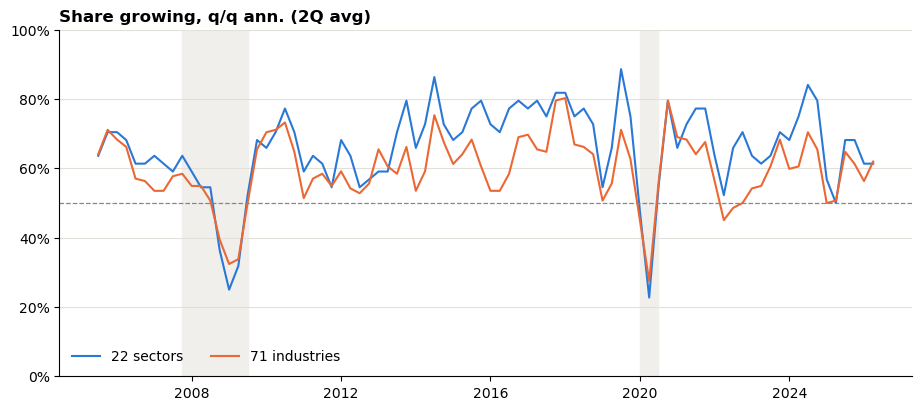

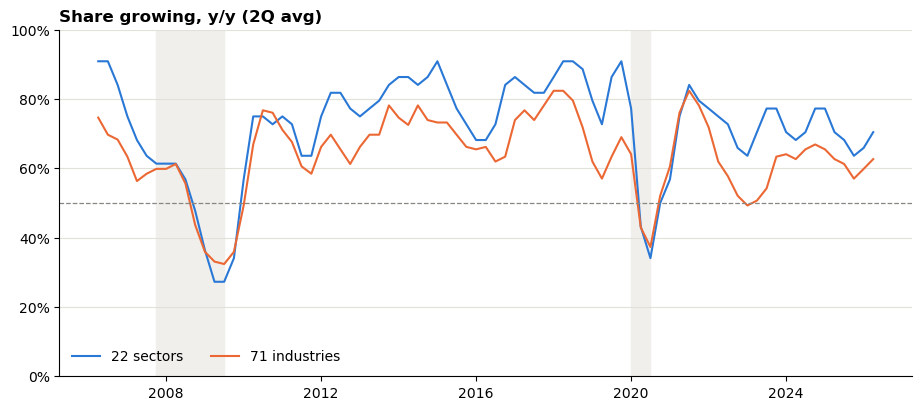

In [5]:
for view in growth:
    fig, ax = plt.subplots()
    for name, color in [("22 sectors", BLUE), ("71 industries", ORANGE)]:
        s = B[(name, view)]["growing"].rolling(2).mean()
        ax.plot(s.index.to_timestamp(), s, color=color, label=name)
    format_ax(ax, f"Share growing, {view} (2Q avg)")

### 2. Share of sectors outpacing GDP growth

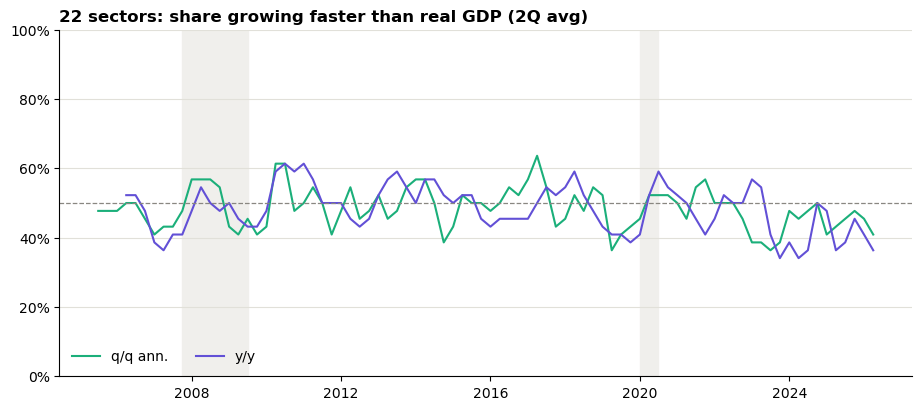

In [6]:
fig, ax = plt.subplots()
for view, color in [("q/q ann.", AQUA), ("y/y", VIOLET)]:
    s = B[("22 sectors", view)]["outpacing_gdp"].rolling(2).mean()
    ax.plot(s.index.to_timestamp(), s, color=color, label=view)
format_ax(ax, "22 sectors: share growing faster than real GDP (2Q avg)")

### 3–5. Weighted vs unweighted share growing

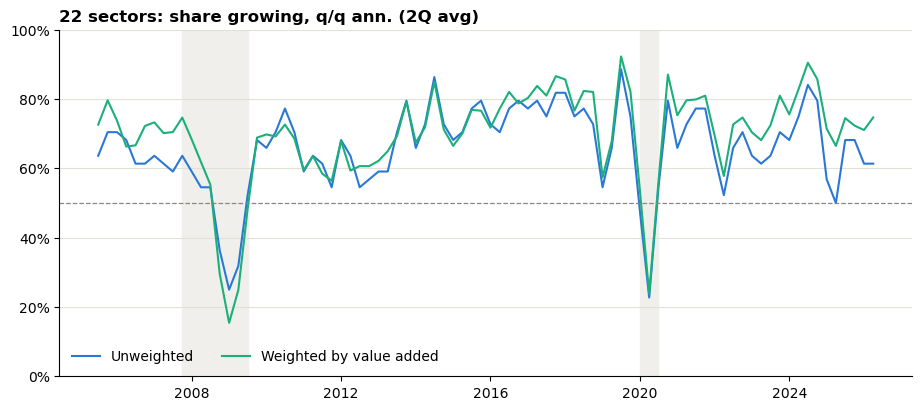

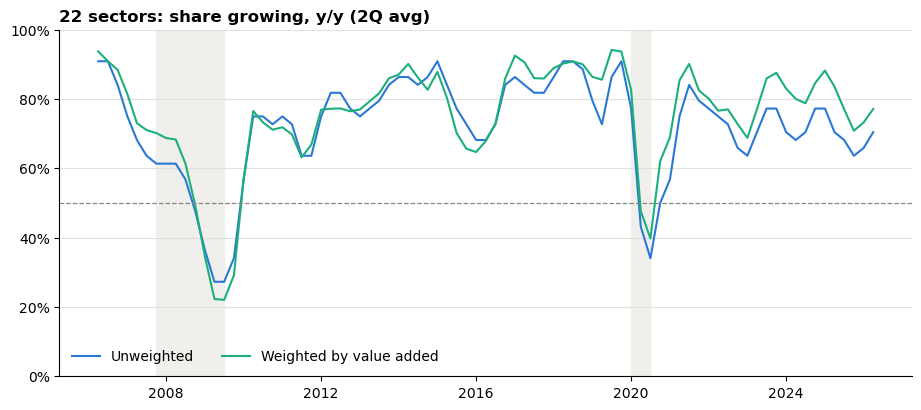

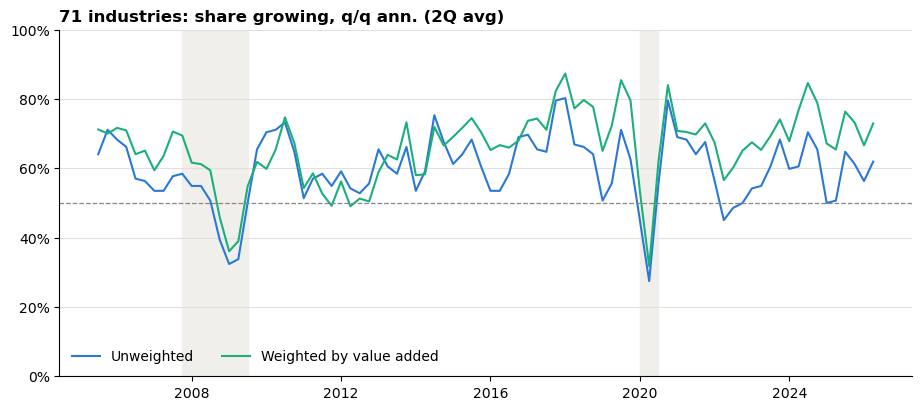

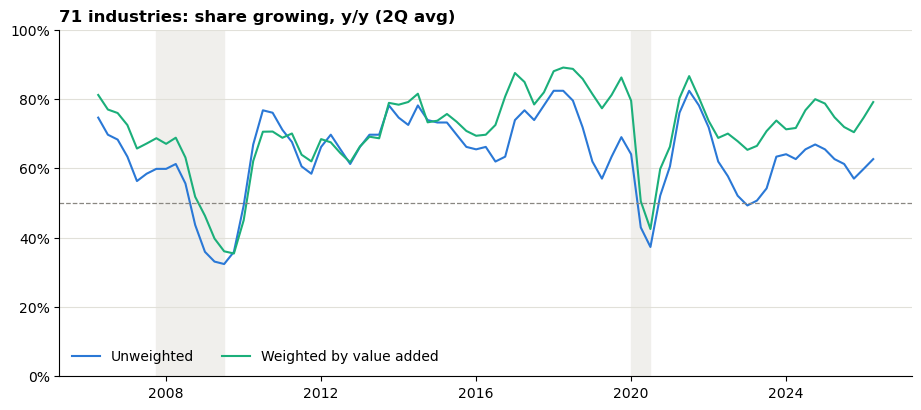

In [7]:
for name in SETS:
    for view in growth:
        fig, ax = plt.subplots()
        for col, label, color in [("growing", "Unweighted", BLUE), ("growing_weighted", "Weighted by value added", AQUA)]:
            s = B[(name, view)][col].rolling(2).mean()
            ax.plot(s.index.to_timestamp(), s, color=color, label=label)
        format_ax(ax, f"{name}: share growing, {view} (2Q avg)")

### 6. Breadth composite, q/q annualized

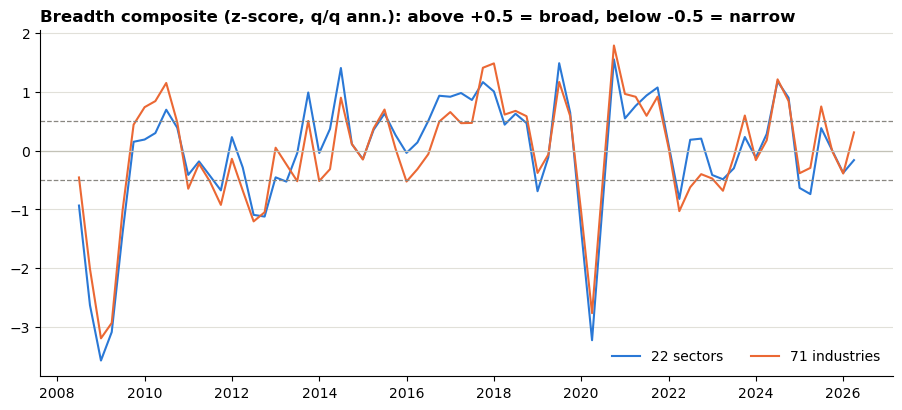

In [8]:
fig, ax = plt.subplots()
for name, color in [("22 sectors", BLUE), ("71 industries", ORANGE)]:
    s = B[(name, "q/q ann.")]["composite"]
    ax.plot(s.index.to_timestamp(), s, color=color, label=name)
for y in (0.5, -0.5):
    ax.axhline(y, color="#898781", lw=0.9, ls="--")
ax.axhline(0, color="#c3c2b7", lw=0.9)
ax.set_title("Breadth composite (z-score, q/q ann.): above +0.5 = broad, below -0.5 = narrow")
ax.legend(loc="lower right", ncol=2)
plt.show()

## 7. Breadth summary
Single-quarter values, not smoothed. Weighted rows use prior-period nominal value-added shares. Rows without an industry label refer to the 22 sectors.

In [9]:
ROWS = [("22 sectors", "growing", "Sectors growing (%)"),
        ("22 sectors", "growing_weighted", "Sectors growing, weighted by value added (%)"),
        ("22 sectors", "weighted_gap", "Sectors: weighted minus unweighted (pts)"),
        ("71 industries", "growing", "Industries growing (%)"),
        ("71 industries", "growing_weighted", "Industries growing, weighted by value added (%)"),
        ("71 industries", "weighted_gap", "Industries: weighted minus unweighted (pts)"),
        ("22 sectors", "median_growth", "Median sector growth (%)"),
        ("22 sectors", "outpacing_gdp", "Sectors outpacing GDP growth (%)"),
        ("22 sectors", "top3_share", "Top-3 share of growth contributions (%)"),
        ("22 sectors", "gdp_ex_top3", "GDP growth ex top-3 contributors (%)")]

tables = {}
for view in growth:
    df = pd.DataFrame({label: B[(name, view)][col] for name, col, label in ROWS})
    t = df.iloc[-2:].T
    t.columns = t.columns.astype(str)
    t["2025 avg"] = df.loc["2025Q1":"2025Q4"].mean()
    t["2014-19 avg"] = df.loc["2014Q1":"2019Q4"].mean()
    tables[view] = t
pd.concat(tables).round(1)

period                                                    2026Q1  2026Q2  \
q/q ann. Sectors growing (%)                                59.1    63.6   
         Sectors growing, weighted by value added (%)       72.4    77.0   
         Sectors: weighted minus unweighted (pts)           13.3    13.4   
         Industries growing (%)                             57.7    66.2   
         Industries growing, weighted by value added (%)    65.4    80.5   
         Industries: weighted minus unweighted (pts)         7.7    14.3   
         Median sector growth (%)                            1.2     1.5   
         Sectors outpacing GDP growth (%)                   36.4    45.5   
         Top-3 share of growth contributions (%)            59.1    48.5   
         GDP growth ex top-3 contributors (%)                0.4     0.6   
y/y      Sectors growing (%)                                72.7    68.2   
         Sectors growing, weighted by value added (%)       77.8    76.5   
         Sectors: weighted minus unweighted (pts)            5.1     8.3   
         Industries growing (%)                             64.8    60.6   
         Industries growing, weighted by value added (%)    79.7    78.6   
         Industries: weighted minus unweighted (pts)        14.9    18.0   
         Median sector growth (%)                            1.3     1.5   
         Sectors outpacing GDP growth (%)                   36.4    36.4   
         Top-3 share of growth contributions (%)            51.4    53.7   
         GDP growth ex top-3 contributors (%)                1.1     0.8   

period                                                    2025 avg  \
q/q ann. Sectors growing (%)                                  59.1   
         Sectors growing, weighted by value added (%)         69.4   
         Sectors: weighted minus unweighted (pts)             10.3   
         Industries growing (%)                               56.0   
         Industries growing, weighted by value added (%)      69.3   
         Industries: weighted minus unweighted (pts)          13.3   
         Median sector growth (%)                              1.3   
         Sectors outpacing GDP growth (%)                     45.5   
         Top-3 share of growth contributions (%)              53.0   
         GDP growth ex top-3 contributors (%)                  0.4   
y/y      Sectors growing (%)                                  67.0   
         Sectors growing, weighted by value added (%)         77.2   
         Sectors: weighted minus unweighted (pts)             10.2   
         Industries growing (%)                               59.9   
         Industries growing, weighted by value added (%)      72.6   
         Industries: weighted minus unweighted (pts)          12.7   
         Median sector growth (%)                              1.3   
         Sectors outpacing GDP growth (%)                     40.9   
         Top-3 share of growth contributions (%)              51.6   
         GDP growth ex top-3 contributors (%)                  0.9   

period                                                    2014-19 avg  
q/q ann. Sectors growing (%)                                     74.6  
         Sectors growing, weighted by value added (%)            77.1  
         Sectors: weighted minus unweighted (pts)                 2.5  
         Industries growing (%)                                  64.0  
         Industries growing, weighted by value added (%)         72.1  
         Industries: weighted minus unweighted (pts)              8.1  
         Median sector growth (%)                                 2.4  
         Sectors outpacing GDP growth (%)                        49.4  
         Top-3 share of growth contributions (%)                 45.1  
         GDP growth ex top-3 contributors (%)                     1.1  
y/y      Sectors growing (%)                                     82.6  
         Sectors growing, weighted by value added (%)            84.

## Top contributing and contracting sectors, latest quarter

In [10]:
last = contrib.index[-1]
latest = pd.DataFrame({"Contribution to GDP growth (pp)": contrib.loc[last, SECTORS],
                       "Growth q/q ann. (%)": growth["q/q ann."].loc[last, SECTORS],
                       "Growth y/y (%)": growth["y/y"].loc[last, SECTORS]}).rename(index=NAMES).round(2)
print(f"Top 5 contributors, {last}")
display(latest.nlargest(5, "Contribution to GDP growth (pp)"))
print(f"Contracting sectors (q/q ann.), largest drag first, {last}")
display(latest[latest["Growth q/q ann. (%)"] < 0].sort_values("Contribution to GDP growth (pp)").head(5))

Top 5 contributors, 2026Q2


,Contribution to GDP growth (pp),Growth q/q ann. (%),Growth y/y (%)
Industry,,,
Real estate & leasing,0.57,4.30,1.62
Information,0.52,9.17,10.26
Durable mfg,0.50,10.20,6.19
Finance & insurance,0.50,5.69,5.71
Wholesale trade,0.33,5.23,3.59


Contracting sectors (q/q ann.), largest drag first, 2026Q2


,Contribution to GDP growth (pp),Growth q/q ann. (%),Growth y/y (%)
Industry,,,
Transport & warehousing,-0.37,-10.81,-4.03
Retail trade,-0.27,-4.53,-0.73
Nondurable mfg,-0.18,-4.04,-3.15
Mining,-0.12,-7.60,-3.34
Mgmt of companies,-0.05,-3.02,1.36
